<a href="https://www.kaggle.com/code/nayonahmedlol/text-emotion-detection-end-to-end-nlp?scriptVersionId=363564469" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

In [1]:
#import library
import numpy as np 
import pandas as pd 

import seaborn as sns 
import matplotlib.pyplot as plt 

import string 
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize 

from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC

from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay

## Load Dataset & Explore Data

In [2]:
#display row data
original=pd.read_csv("/kaggle/input/datasets/abhrajaiswal/emotions-detection-text-dataset/emotions.txt")
original.head()

,i didnt feel humiliated;sadness
0,i can go from feeling so hopeless to so damned...
1,im grabbing a minute to post i feel greedy wro...
2,i am ever feeling nostalgic about the fireplac...
3,i am feeling grouchy;anger
4,ive been feeling a little burdened lately wasn...


In [3]:
# assign column names
df=pd.read_csv(
    "/kaggle/input/datasets/abhrajaiswal/emotions-detection-text-dataset/emotions.txt", 
    sep=';', 
    header=None, 
    names=[
        'text', 
        'emotion'
    ]
)

In [4]:
df.head()

,text,emotion
0,i didnt feel humiliated,sadness
1,i can go from feeling so hopeless to so damned...,sadness
2,im grabbing a minute to post i feel greedy wrong,anger
3,i am ever feeling nostalgic about the fireplac...,love
4,i am feeling grouchy,anger


/tmp/ipykernel_16/4069201231.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(


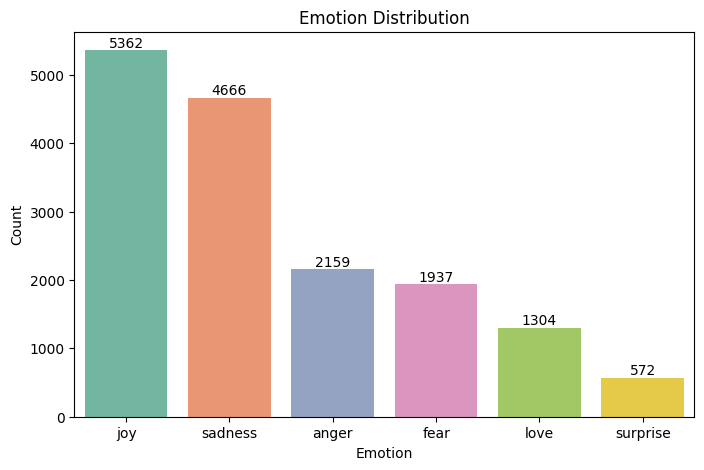

emotion
anger       2159
fear        1937
joy         5362
love        1304
sadness     4666
surprise     572
Name: count, dtype: int64


In [5]:
# Analyze the distribution of emotion classes
value_count=df['emotion'].value_counts().sort_index()
plt.figure(figsize=(8,5))

ax = sns.countplot(
    data=df,
    x="emotion",
    order=df["emotion"].value_counts().index,
    palette="Set2"
)

plt.title("Emotion Distribution")
plt.xlabel("Emotion")
plt.ylabel("Count")

for container in ax.containers:
    ax.bar_label(container)

plt.show()
print(value_count)

#### Label Encoding

In [6]:
label_encoder=LabelEncoder()
df['emotion']=label_encoder.fit_transform(df['emotion'])
df

,text,emotion
0,i didnt feel humiliated,4
1,i can go from feeling so hopeless to so damned...,4
2,im grabbing a minute to post i feel greedy wrong,0
3,i am ever feeling nostalgic about the fireplac...,3
4,i am feeling grouchy,0
...,...,...
15995,i just had a very brief time in the beanbag an...,4
15996,i am now turning and i feel pathetic that i am...,4
15997,i feel strong and good overall,2
15998,i feel like this was such a rude comment and i...,0


#### Making text lowercase

In [7]:
df['text']=df['text'].apply(lambda x : x.lower())

#### Removing punctuations

In [8]:
def remove_punc(txt): 
    return txt.translate(str.maketrans('','',string.punctuation))

In [9]:
df['text']=df['text'].apply(remove_punc)

#### Removing Numbers

In [10]:
def remove_numbers(txt):
    new = ""
    for i in txt:
        if not i.isdigit():
            new = new + i
    return new

df['text'] = df['text'].apply(remove_numbers)

#### Removing Emojis

In [11]:
def remove_emojis(txt):
    new = ""
    for i in txt:
        if i.isascii():
            new += i
    return new

df['text'] = df['text'].apply(remove_emojis)

#### Removing Stopwords

In [12]:
nltk.download('punkt')
nltk.download('stopwords')

[nltk_data] Downloading package punkt to /usr/share/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to /usr/share/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [13]:
stop_words = set(stopwords.words('english'))

In [14]:
df.loc[1]['text']

'i can go from feeling so hopeless to so damned hopeful just from being around someone who cares and is awake'

In [15]:
def remove(txt):
  words = txt.split()
  cleaned = []
  for i in words:
    if not i in stop_words:
      cleaned.append(i)

  return ' '.join(cleaned)

In [16]:
df['text'] = df['text'].apply(remove)

In [17]:
df.loc[1]['text']

'go feeling hopeless damned hopeful around someone cares awake'

In [18]:
df.head()

,text,emotion
0,didnt feel humiliated,4
1,go feeling hopeless damned hopeful around some...,4
2,im grabbing minute post feel greedy wrong,0
3,ever feeling nostalgic fireplace know still pr...,3
4,feeling grouchy,0


#### Train-Test Split 

In [19]:
X=df['text']
y=df['emotion']

In [20]:
X_train,X_test,y_train,y_test=train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
    
)

### TF-IDF Vectorization

In [21]:
tfidf=TfidfVectorizer()

X_train_tfidf=tfidf.fit_transform(X_train)
X_test_tfidf=tfidf.transform(X_test)

print(X_train_tfidf.shape)
print(X_test_tfidf.shape)

(12800, 13361)
(3200, 13361)


## Train Logistic Regression

In [22]:
lr_model=LogisticRegression(max_iter=1000)
lr_model.fit(X_train_tfidf , y_train)

LogisticRegression(max_iter=1000)

In [23]:
# Prediction
lr_pred=lr_model.predict(X_test_tfidf)

In [24]:
# Accuracy
lr_accuracy=accuracy_score(
    lr_pred,
    y_test
)

print(f"Logistic Regression Accuracy: {lr_accuracy}")

Logistic Regression Accuracy: 0.8628125


In [25]:
# Classification Report
print(classification_report(y_test,lr_pred))

              precision    recall  f1-score   support

           0       0.90      0.81      0.86       427
           1       0.86      0.76      0.81       397
           2       0.81      0.96      0.88      1021
           3       0.90      0.61      0.73       296
           4       0.90      0.94      0.92       946
           5       0.88      0.47      0.61       113

    accuracy                           0.86      3200
   macro avg       0.88      0.76      0.80      3200
weighted avg       0.87      0.86      0.86      3200



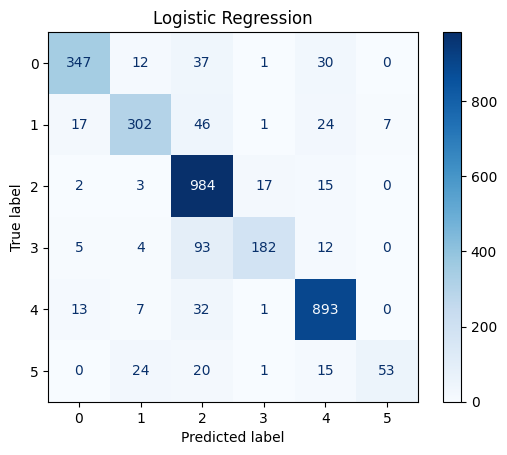

In [26]:
# Confusion Matrix
ConfusionMatrixDisplay.from_estimator(
    lr_model,
    X_test_tfidf,
    y_test,
    cmap="Blues"
)

plt.title("Logistic Regression")
plt.show()

## Train Linear SVM

In [27]:
svm_model=LinearSVC()
svm_model.fit(X_train_tfidf,y_train)

LinearSVC()

In [28]:
# prediction
svm_pred=svm_model.predict(X_test_tfidf)

In [29]:
# Accuracy
svm_accuracy = accuracy_score(y_test, svm_pred)

print(f"Linear SVM Accuracy: {svm_accuracy}")

Linear SVM Accuracy: 0.891875


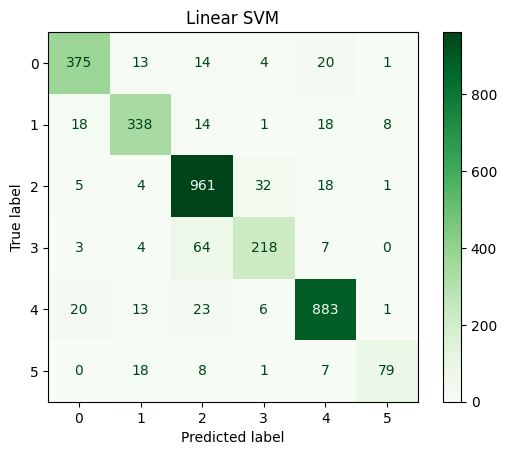

In [30]:
# ConfusionMatrix
ConfusionMatrixDisplay.from_estimator(
    svm_model,
    X_test_tfidf,
    y_test,
    cmap="Greens"
)

plt.title("Linear SVM")
plt.show()

In [31]:
# Classification Report
print(classification_report(y_test,svm_pred))

              precision    recall  f1-score   support

           0       0.89      0.88      0.88       427
           1       0.87      0.85      0.86       397
           2       0.89      0.94      0.91      1021
           3       0.83      0.74      0.78       296
           4       0.93      0.93      0.93       946
           5       0.88      0.70      0.78       113

    accuracy                           0.89      3200
   macro avg       0.88      0.84      0.86      3200
weighted avg       0.89      0.89      0.89      3200



## 2 Model Compare

In [32]:
print(f"Logistic Regression : {lr_accuracy:.4f}")
print(f"Linear SVM          : {svm_accuracy:.4f}")

Logistic Regression : 0.8628
Linear SVM          : 0.8919
